<a href="https://colab.research.google.com/github/nowrin-12/rl-5g-scheduler/blob/main/phase_2schedulers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

N_USERS = 10
CELL_RADIUS = 500
MIN_DIST = 50
BANDWIDTH = 1e6
TX_POWER_DBM = 30
NOISE_DBM = -174 + 10*np.log10(BANDWIDTH) + 9
DT = 0.01
SPEED = 10
PACKET_BITS = 12000
ARRIVAL_LAMBDA = 1

class Tower:
    def __init__(self, n_users=10, seed=0):
        self.n_users = n_users
        self.rng = np.random.default_rng(seed)
        self.avg_window = 100
        self.reset()

    def reset(self):
        r = np.sqrt(self.rng.uniform(MIN_DIST**2, CELL_RADIUS**2, self.n_users))
        theta = self.rng.uniform(0, 2*np.pi, self.n_users)
        self.pos = np.stack([r*np.cos(theta), r*np.sin(theta)], axis=1)
        self.heading = self.rng.uniform(0, 2*np.pi, self.n_users)
        self.buffer = np.zeros(self.n_users)
        self.avg_tp = np.full(self.n_users, 1e5)
        self.t = 0
        self.rates = self._rates()
        return self.rates

    def _rates(self):
        dist_km = np.maximum(np.linalg.norm(self.pos, axis=1), 1.0)/1000
        pl = 128.1 + 37.6*np.log10(dist_km)
        fading = 10*np.log10(self.rng.exponential(1.0, self.n_users))
        snr_db = np.clip(TX_POWER_DBM - pl + fading - NOISE_DBM, -10, 30)
        return BANDWIDTH*np.log2(1 + 10**(snr_db/10))

    def _move(self):
        self.heading += self.rng.normal(0, 0.3, self.n_users)
        self.pos += SPEED*DT*np.stack([np.cos(self.heading), np.sin(self.heading)], axis=1)
        dist = np.linalg.norm(self.pos, axis=1)
        far, near = dist > CELL_RADIUS, dist < MIN_DIST
        self.pos[far] *= (CELL_RADIUS/dist[far])[:, None]
        self.pos[near] *= (MIN_DIST/dist[near])[:, None]
        self.heading[far | near] += np.pi

    def step(self, user):
        served = min(self.buffer[user], self.rates[user]*DT)
        self.buffer[user] -= served
        served_rate = np.zeros(self.n_users)
        served_rate[user] = served/DT
        self.avg_tp = (1 - 1/self.avg_window)*self.avg_tp + (1/self.avg_window)*served_rate
        self.buffer += self.rng.poisson(ARRIVAL_LAMBDA, self.n_users)*PACKET_BITS
        self._move()
        self.rates = self._rates()
        self.t += 1
        return served

In [2]:
def round_robin(tower):
    for i in range(tower.n_users):
        u = (tower.t + i) % tower.n_users
        if tower.buffer[u] > 0:
            return u
    return 0

def max_ci(tower):
    score = np.where(tower.buffer > 0, tower.rates, -np.inf)
    return int(np.argmax(score))

def prop_fair(tower):
    score = np.where(tower.buffer > 0, tower.rates / tower.avg_tp, -np.inf)
    return int(np.argmax(score))

In [3]:
def run(scheduler, n_steps=2000, seed=0, n_users=10):
    tower = Tower(n_users, seed)
    delivered = np.zeros(n_users)
    queue_sum = 0.0
    for _ in range(n_steps):
        u = scheduler(tower)
        delivered[u] += tower.step(u)
        queue_sum += tower.buffer.sum()
    seconds = n_steps * DT
    throughput = delivered.sum() / seconds
    jain = delivered.sum()**2 / (n_users * (delivered**2).sum() + 1e-9)
    delay = (queue_sum / n_steps) / (throughput + 1e-9)
    return {"throughput_mbps": throughput/1e6, "fairness": jain, "delay_ms": delay*1000}

for name, f in [("Round Robin", round_robin), ("Max C/I", max_ci), ("Prop. Fair", prop_fair)]:
    print(name, run(f))

Round Robin {'throughput_mbps': np.float64(7.076822750379043), 'fairness': np.float64(0.9527914131116325), 'delay_ms': np.float64(7091.764196918574)}
Max C/I {'throughput_mbps': np.float64(3.7833832630106867), 'fairness': np.float64(0.32909385678496894), 'delay_ms': np.float64(21870.32626952056)}
Prop. Fair {'throughput_mbps': np.float64(8.767172194937492), 'fairness': np.float64(0.9824165772861346), 'delay_ms': np.float64(3798.715092623918)}


In [4]:
schedulers = {"Round Robin": round_robin, "Max C/I": max_ci, "Prop. Fair": prop_fair}
rows = []
for name, f in schedulers.items():
    for seed in range(20):
        r = run(f, seed=seed)
        r["scheduler"] = name
        rows.append(r)

df = pd.DataFrame(rows)
summary = df.groupby("scheduler").agg(["mean", "std"]).round(2)
summary

throughput_mbps       fairness        delay_ms         
                       mean   std     mean   std      mean      std
scheduler                                                          
Max C/I                4.71  0.98     0.46  0.11  16448.11  4809.56
Prop. Fair             8.94  0.28     0.98  0.00   3487.16   453.07
Round Robin            7.29  0.43     0.96  0.01   6535.22  1006.88

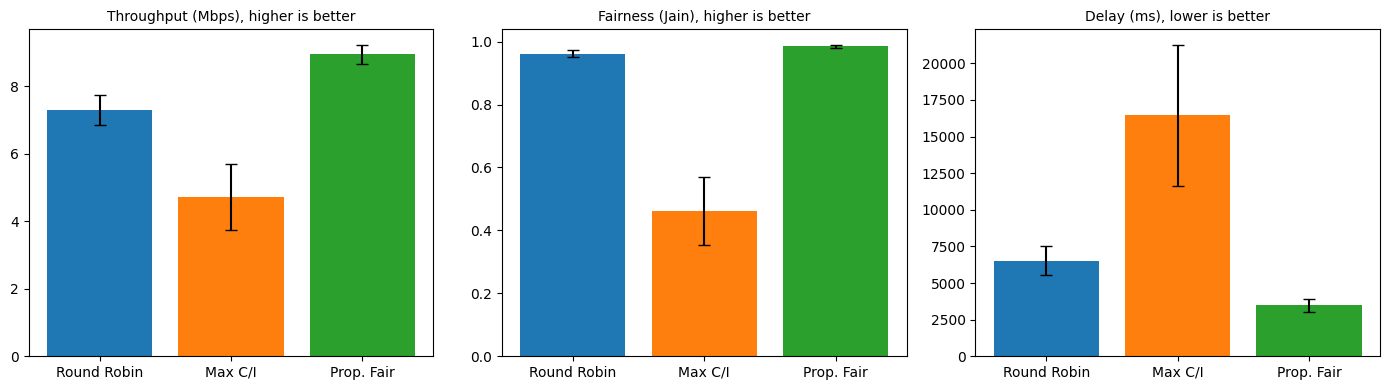

In [5]:
metrics = [("throughput_mbps", "Throughput (Mbps), higher is better"),
           ("fairness", "Fairness (Jain), higher is better"),
           ("delay_ms", "Delay (ms), lower is better")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (col, title) in zip(axes, metrics):
    m = df.groupby("scheduler")[col].mean()[list(schedulers)]
    s = df.groupby("scheduler")[col].std()[list(schedulers)]
    ax.bar(m.index, m.values, yerr=s.values, capsize=4, color=["tab:blue", "tab:orange", "tab:green"])
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.savefig("scheduler_comparison.png", dpi=150)
plt.show()

In [6]:
results = []
for lam in [0.5, 1, 3]:
    ARRIVAL_LAMBDA = lam
    for name, f in schedulers.items():
        for seed in range(10):
            r = run(f, seed=seed)
            r.update({"scheduler": name, "load": lam})
            results.append(r)
ARRIVAL_LAMBDA = 1

load_df = pd.DataFrame(results)
load_df.groupby(["load", "scheduler"])[["throughput_mbps", "fairness", "delay_ms"]].mean().round(2)

throughput_mbps  fairness  delay_ms
load scheduler                                       
0.5  Max C/I                 3.48      0.66   7443.00
     Prop. Fair              5.49      0.99    999.58
     Round Robin             5.86      1.00    305.79
1.0  Max C/I                 4.70      0.46  16429.26
     Prop. Fair              8.95      0.99   3474.72
     Round Robin             7.31      0.96   6494.30
3.0  Max C/I                 7.69      0.29  38657.16
     Prop. Fair              8.97      0.99  30194.90
     Round Robin             7.32      0.96  39409.45